# Intelligent 3DCP: Mechanical strength prediction

In [1]:
# Import the libraries
import warnings, os, pickle, copy
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn imports
from sklearn.model_selection   import train_test_split, GridSearchCV
from sklearn.preprocessing     import StandardScaler, OneHotEncoder
from sklearn.compose           import ColumnTransformer
from sklearn.pipeline          import Pipeline
from sklearn.linear_model      import Ridge
from sklearn.naive_bayes       import GaussianNB
from sklearn.base              import BaseEstimator, RegressorMixin
from sklearn.preprocessing     import KBinsDiscretizer
from sklearn.metrics           import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor


# gradient boost
import xgboost  as xgb
import lightgbm as lgb

# pytoreh imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [2]:
print("=" * 50)
print(f"  PyTorch      : {torch.__version__}")
print(f"  XGBoost      : {xgb.__version__}")
print(f"  LightGBM     : {lgb.__version__}")
print(f"  Device       : {DEVICE}")
print("=" * 50)

  PyTorch      : 2.11.0+cu130
  XGBoost      : 3.2.0
  LightGBM     : 4.6.0
  Device       : cuda


In [3]:
df = pd.read_csv('ConcreteXAI/Data.csv')

df=df.drop(columns="id")
print("Shape :", df.shape)
print("Columns:", df.columns.tolist())
df.info()


Shape : (4420, 11)
Columns: ['Type_of_cement', 'Brand', 'Additives', 'Type_of_aggregates', 'Design_Fc_Mpa', 'Curing_age_days', 'Cs_Mpa', 'Ts_Mpa', 'Fs_Mpa', 'Er_ohm-cm', 'UPV_m/s']
<class 'pandas.DataFrame'>
RangeIndex: 4420 entries, 0 to 4419
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Type_of_cement      4420 non-null   str    
 1   Brand               4420 non-null   str    
 2   Additives           4420 non-null   str    
 3   Type_of_aggregates  4420 non-null   str    
 4   Design_Fc_Mpa       4420 non-null   int64  
 5   Curing_age_days     4420 non-null   int64  
 6   Cs_Mpa              4420 non-null   float64
 7   Ts_Mpa              3460 non-null   float64
 8   Fs_Mpa              1760 non-null   float64
 9   Er_ohm-cm           4420 non-null   float64
 10  UPV_m/s             4420 non-null   float64
dtypes: float64(5), int64(2), str(4)
memory usage: 380.0 KB


## Dataset Description

- **Type_of_cement**  
  Categorical — cement grade/type (4 unique values)

- **Brand**  
  Categorical — cement brand: CEMEX / Apasco

- **Additives**  
  Categorical — additive type (5 unique values)

- **Type_of_aggregates**  
  Categorical — aggregate shape (4 unique values)

- **Design_F'c_(Mpa)**  
  Numerical — design compressive target [MPa] (range: 25–35)

- **Curing_age_(days)**  
  Numerical — specimen age at test [days] (range: 3–120)

- **Cs_(Mpa)**  
  Target — compressive strength [MPa] (4420 rows)

- **Ts_(Mpa)**  
  Target — indirect tensile strength [MPa] (3460 rows)

- **Fs_(Mpa)**  
  Target — flexural / modulus-of-rupture [MPa] (1760 rows)

- **Er_(ohm-cm)**  
  Numerical — electrical resistivity [Ω·cm] (Non-Destructive Test)

- **UPV_(m/s)**  
  Numerical — ultrasonic pulse velocity [m/s] (Non-Destructive Test)

In [4]:
print("\n=== Descriptive Statistics ===")
df.describe(include='all').T



=== Descriptive Statistics ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type_of_cement,4420,4,CPC 30R,1300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Brand,4420,2,CEMEX,3540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Additives,4420,5,No_additions,2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type_of_aggregates,4420,4,Crushed,1540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Design_Fc_Mpa,4420.0,NaN,NaN,NaN,28.959276,3.509038,25.0,25.0,28.0,30.0,35.0
Curing_age_days,4420.0,NaN,NaN,NaN,40.443439,33.308785,3.0,14.0,28.0,60.0,120.0
Cs_Mpa,4420.0,NaN,NaN,NaN,31.193113,9.588822,5.0823,24.9624,31.8537,36.0754,55.7092
Ts_Mpa,3460.0,NaN,NaN,NaN,2.481807,0.875311,0.5311,2.051875,2.3584,2.941725,5.272
Fs_Mpa,1760.0,NaN,NaN,NaN,3.421582,2.369809,0.3367,1.1719,3.1381,5.5645,8.0869
Er_ohm-cm,4420.0,NaN,NaN,NaN,6.760444,2.97059,1.8312,4.639225,6.07035,7.4613,16.1693


        Count      %
Ts_Mpa    960  21.72
Fs_Mpa   2660  60.18


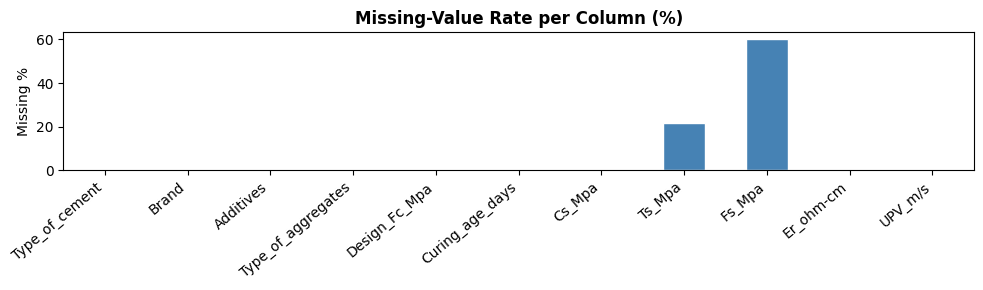

In [5]:
missing = df.isnull().sum()
pct     = (missing / len(df) * 100).round(2)
mv      = pd.DataFrame({'Count': missing, '%': pct})
print(mv[mv['Count'] > 0])

fig, ax = plt.subplots(figsize=(10, 3))
mv['%'].plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Missing-Value Rate per Column (%)', fontweight='bold')
ax.set_ylabel('Missing %')
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right')
plt.tight_layout(); plt.show()

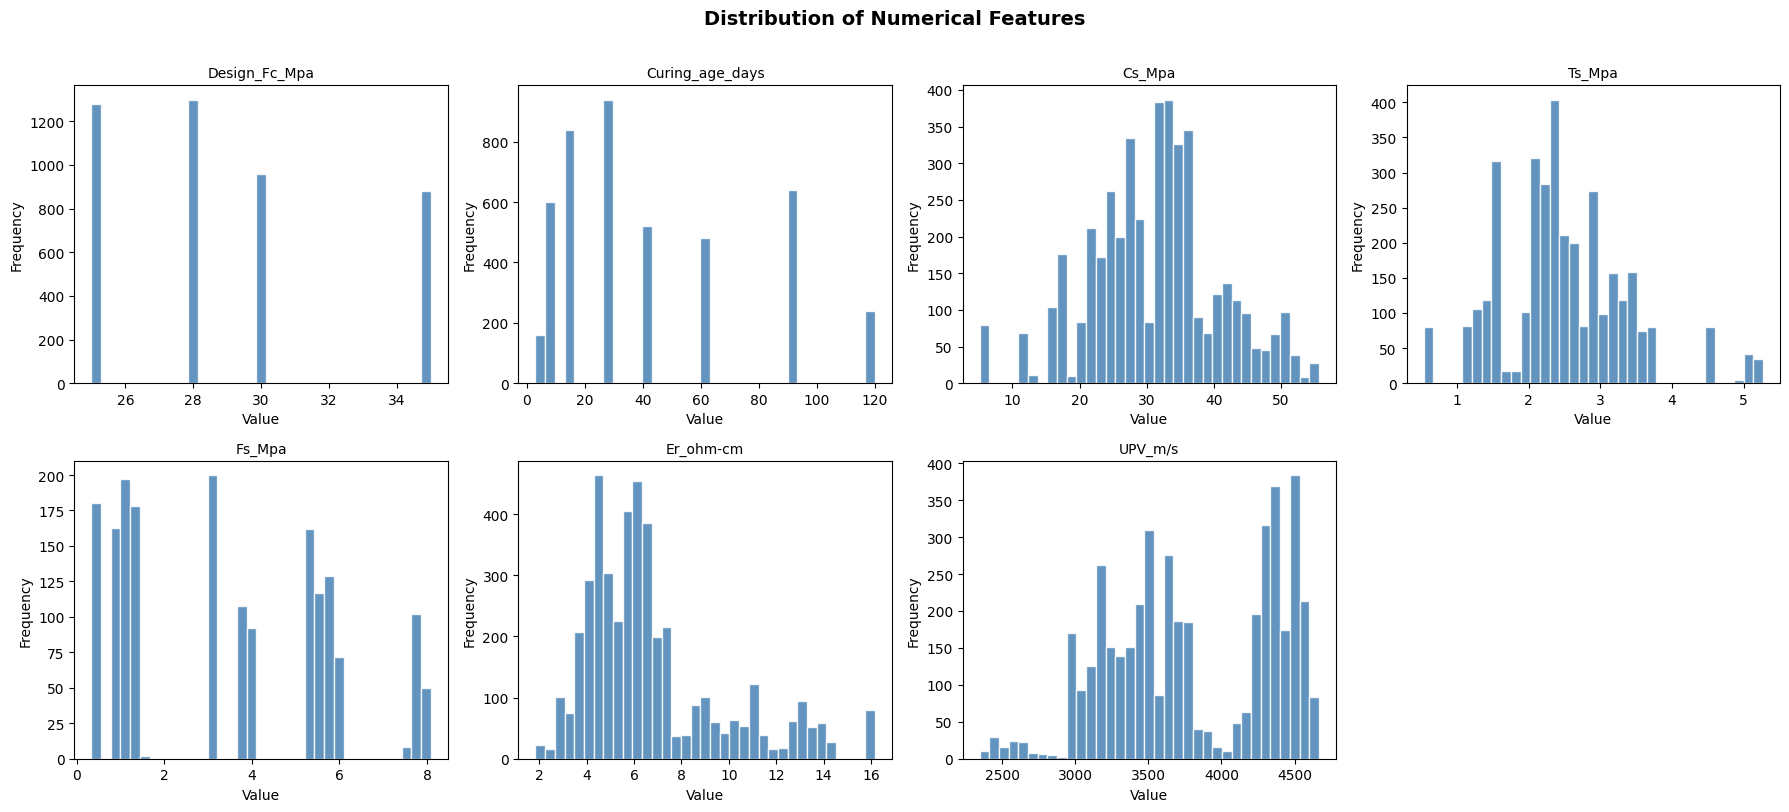

In [6]:
# EDA- numerical features
num_cols = ["Design_Fc_Mpa", 'Curing_age_days',
            'Cs_Mpa', 'Ts_Mpa', 'Fs_Mpa',
            'Er_ohm-cm', 'UPV_m/s']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    axes[i].hist(df[col].dropna(), bins=35,
                 color='steelblue', edgecolor='white', alpha=0.85)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('Value'); axes[i].set_ylabel('Frequency')
axes[-1].set_visible(False)
plt.suptitle('Distribution of Numerical Features',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()


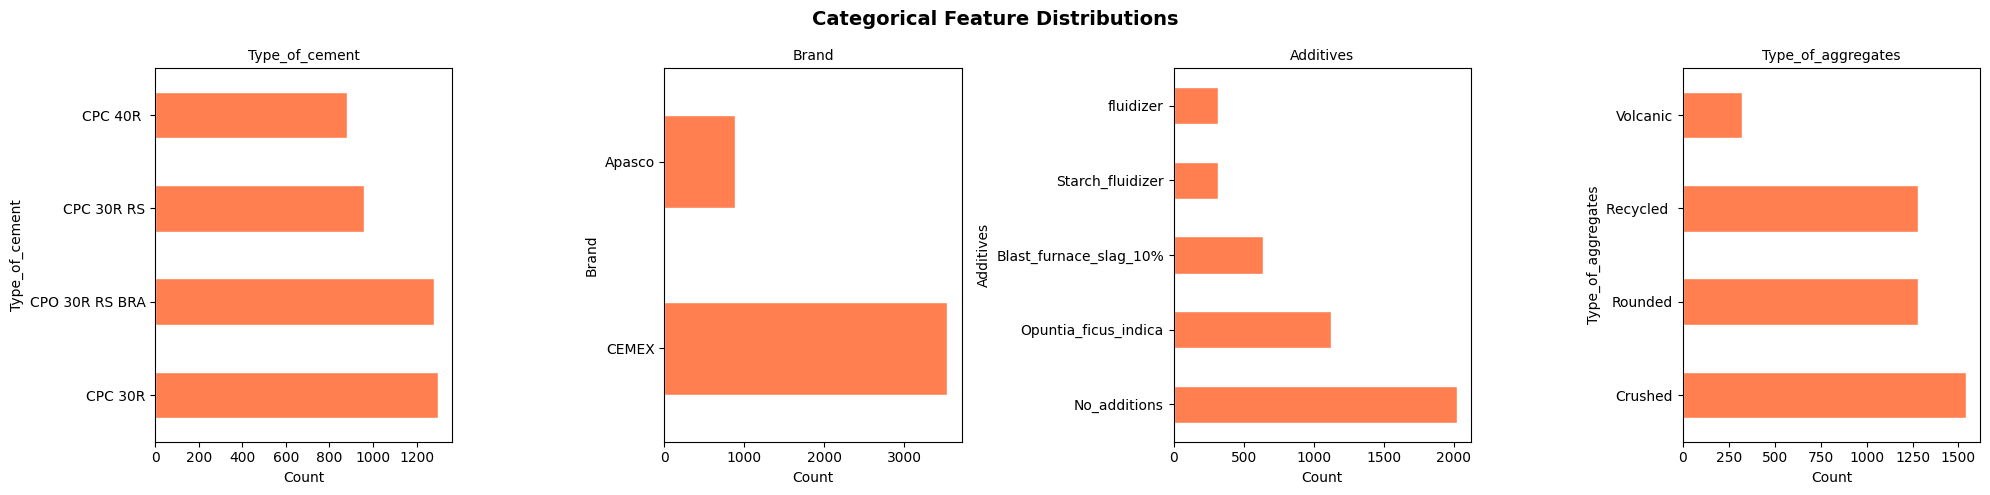

In [7]:
# EDA - Catagorical
cat_cols = ['Type_of_cement', 'Brand', 'Additives', 'Type_of_aggregates']
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, col in zip(axes, cat_cols):
    df[col].value_counts().plot(kind='barh', ax=ax,
                                color='coral', edgecolor='white')
    ax.set_title(col, fontsize=10); ax.set_xlabel('Count')
plt.suptitle('Categorical Feature Distributions', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


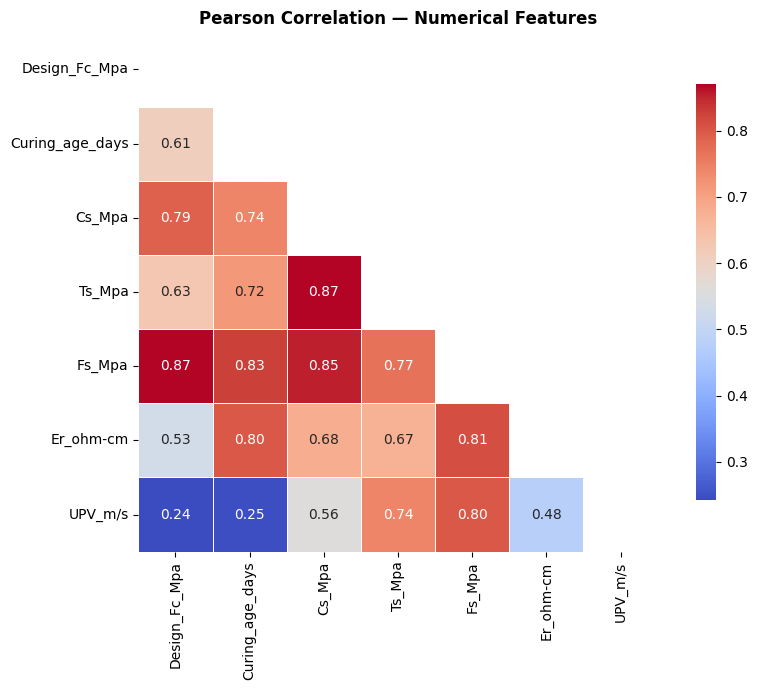

In [8]:
# corealtion heatmap
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            square=True, linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Pearson Correlation — Numerical Features', fontweight='bold')
plt.tight_layout(); plt.show()


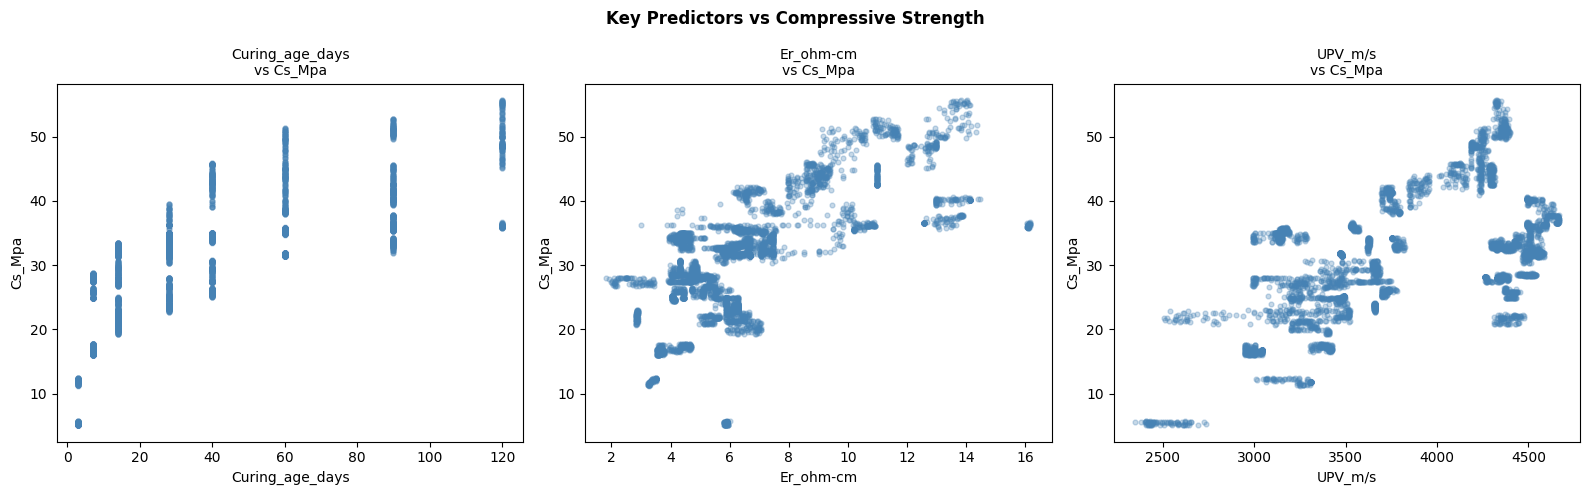

In [9]:

pairs = [('Curing_age_days', 'Cs_Mpa'),
         ('Er_ohm-cm',        'Cs_Mpa'),
         ('UPV_m/s',          'Cs_Mpa')]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (x, y) in zip(axes, pairs):
    sub = df[[x, y]].dropna()
    ax.scatter(sub[x], sub[y], alpha=0.3, s=12, color='steelblue')
    ax.set_xlabel(x); ax.set_ylabel(y)
    ax.set_title(f'{x}\nvs {y}', fontsize=10)
plt.suptitle('Key Predictors vs Compressive Strength', fontweight='bold')
plt.tight_layout(); plt.show()


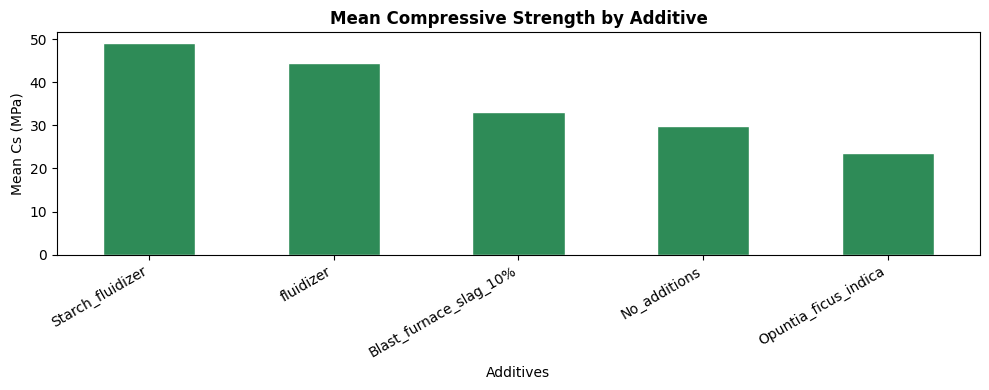

In [10]:
# 
mean_cs = (df.groupby('Additives')['Cs_Mpa']
             .mean().sort_values(ascending=False))
fig, ax = plt.subplots(figsize=(10, 4))
mean_cs.plot(kind='bar', ax=ax, color='seagreen', edgecolor='white')
ax.set_title('Mean Compressive Strength by Additive', fontweight='bold')
ax.set_ylabel('Mean Cs (MPa)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout(); plt.show()


In [11]:
# ── Cell 12 · Global Config — Features / Targets / Splits ────────────────────
FEATURE_COLS = ['Type_of_cement', 'Brand', 'Additives', 'Type_of_aggregates',
                "Design_Fc_Mpa", 'Curing_age_days','Er_ohm-cm', 'UPV_m/s']

CAT_COLS = ['Type_of_cement', 'Brand', 'Additives', 'Type_of_aggregates']
NUM_COLS = ["Design_Fc_Mpa", 'Curing_age_days','Er_ohm-cm', 'UPV_m/s']

TARGETS = {'Cs': 'Cs_Mpa', 'Ts': 'Ts_Mpa', 'Fs': 'Fs_Mpa'}

SAVE_DIR = 'saved_models'
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"Models will be saved to → ./{SAVE_DIR}/")


Models will be saved to → ./saved_models/


In [12]:
# ── Cell 13 · Preprocessing Pipeline + Dataset Splits ────────────────────────
# ColumnTransformer: OHE for categorical, StandardScaler for numerical
preprocessor = ColumnTransformer(transformers=[
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS),
    ('scl', StandardScaler(), NUM_COLS),
])

def make_splits(target_col, val_size=0.30, seed=42):
    """
    70 / 30  train / validation split.
    Rows where target is NaN are dropped only for this target.
    Returns X_train, X_val, y_train, y_val.
    """
    sub = df[FEATURE_COLS + [target_col]].dropna(subset=[target_col]).copy()
    X, y = sub[FEATURE_COLS], sub[target_col].values

    X_tr, X_va, y_tr, y_va = train_test_split(
        X, y, test_size=val_size, random_state=seed
    )

    print(f"  {target_col:15s} → train {len(y_tr):4d} | val {len(y_va):4d}")
    return X_tr, X_va, y_tr, y_va

print("=== Split sizes (70 / 15 / 15) ===")
splits = {name: make_splits(col) for name, col in TARGETS.items()}


=== Split sizes (70 / 15 / 15) ===
  Cs_Mpa          → train 3094 | val 1326
  Ts_Mpa          → train 2422 | val 1038
  Fs_Mpa          → train 1232 | val  528


In [13]:
def metrics(y_true, y_pred, n_features):
    n   = len(y_true)
    r2  = r2_score(y_true, y_pred)
    return {
        'RMSE'   : float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE'    : float(mean_absolute_error(y_true, y_pred)),
        'R²'     : float(r2),
        'Adj.R²' : float(1 - (1 - r2) * (n - 1) / (n - n_features - 1)),
    }

def eval_pipe(pipe, X_tr, X_va, y_tr, y_va, n_feat, label=''):
    """Print train / validation metrics for an sklearn pipeline."""
    rows = []
    
    for sname, X, y in [
        ('Train', X_tr, y_tr),
        ('Val',   X_va, y_va)
    ]:
        m = metrics(y, pipe.predict(X), n_feat)
        rows.append({'Split': sname, **m})
    
    tbl = pd.DataFrame(rows).set_index('Split')[['RMSE','MAE','R²','Adj.R²']]
    
    if label:
        print(f"\n── {label} ──")
    
    print(tbl.round(4).to_string())
    return tbl


In [14]:
lr_results = {}

for name, col in TARGETS.items():
    X_tr, X_va, y_tr, y_va = splits[name]
    X_tv = pd.concat([X_tr, X_va])
    y_tv = np.concatenate([y_tr, y_va])

    pipe = Pipeline([
        ('pre', preprocessor),
        ('mdl', Ridge())
    ])

    gs = GridSearchCV(
        pipe,
        {'mdl__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]},
        cv=5,
        scoring='r2',
        n_jobs=-1
    )

    gs.fit(X_tv, y_tv)

    best = gs.best_estimator_

    best.fit(X_tr, y_tr)

    n_feat = best['pre'].transform(X_tr[:1]).shape[1]

    print(f"\n{'='*55}\n[Ridge] {col}  best α={gs.best_params_['mdl__alpha']}")

    eval_pipe(best, X_tr, X_va, y_tr, y_va, n_feat)
    path = os.path.join(SAVE_DIR, f'ridge_{name}.pkl')
    pickle.dump(best, open(path, 'wb'))
    print(f"  💾 {path}")

    lr_results[name] = best


[Ridge] Cs_Mpa  best α=0.1
         RMSE     MAE      R²  Adj.R²
Split                                
Train  3.0102  2.4013  0.9000  0.8993
Val    3.0423  2.4213  0.9026  0.9012
  💾 saved_models\ridge_Cs.pkl

[Ridge] Ts_Mpa  best α=0.1
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.2594  0.1934  0.9099  0.9092
Val    0.2524  0.1891  0.9213  0.9200
  💾 saved_models\ridge_Ts.pkl

[Ridge] Fs_Mpa  best α=0.1
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.2712  0.1949  0.9869  0.9867
Val    0.2751  0.1990  0.9865  0.9862
  💾 saved_models\ridge_Fs.pkl


In [15]:
class NaiveBayesRegressor(BaseEstimator, RegressorMixin):
    def __init__(self, n_bins=20, var_smoothing=1e-9):
        self.n_bins        = n_bins
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        self.binner_ = KBinsDiscretizer(
            n_bins=self.n_bins, encode='ordinal', strategy='quantile')
        y_b = self.binner_.fit_transform(
            y.reshape(-1, 1)).ravel().astype(int)
        self.nb_ = GaussianNB(var_smoothing=self.var_smoothing)
        self.nb_.fit(X, y_b)
        self.bin_medians_ = np.array([
            np.median(y[y_b == b]) if (y_b == b).any() else 0.0
            for b in range(self.n_bins)
        ])
        return self

    def predict(self, X):
        pred_b = self.nb_.predict(X).astype(int)
        pred_b = np.clip(pred_b, 0, len(self.bin_medians_) - 1)
        return self.bin_medians_[pred_b]

nb_results = {}

nb_results = {}

for name, col in TARGETS.items():
    X_tr, X_va, y_tr, y_va = splits[name]

    X_tv = pd.concat([X_tr, X_va])
    y_tv = np.concatenate([y_tr, y_va])

    pipe = Pipeline([
        ('pre', preprocessor),
        ('mdl', NaiveBayesRegressor())
    ])

    gs = GridSearchCV(
        pipe,
        {
            'mdl__n_bins': [10, 20, 30],
            'mdl__var_smoothing': [1e-9, 1e-7, 1e-5],
        },
        cv=5,
        scoring='r2',
        n_jobs=-1
    )

    gs.fit(X_tv, y_tv)
    best = gs.best_estimator_
    best.fit(X_tr, y_tr)

    n_feat = best['pre'].transform(X_tr[:1]).shape[1]

    print(f"\n{'='*55}\n[Naive Bayes] {col}  best={gs.best_params_}")
    eval_pipe(best, X_tr, X_va, y_tr, y_va, n_feat)

    path = os.path.join(SAVE_DIR, f'nb_{name}.pkl')
    pickle.dump(best, open(path, 'wb'))
    print(f"  💾 {path}")

    nb_results[name] = best



[Naive Bayes] Cs_Mpa  best={'mdl__n_bins': 30, 'mdl__var_smoothing': 1e-05}
         RMSE     MAE      R²  Adj.R²
Split                                
Train  3.2891  2.2534  0.8806  0.8798
Val    3.2608  2.1726  0.8881  0.8865
  💾 saved_models\nb_Cs.pkl

[Naive Bayes] Ts_Mpa  best={'mdl__n_bins': 30, 'mdl__var_smoothing': 1e-05}
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.4465  0.2864  0.7330  0.7311
Val    0.3971  0.2559  0.8053  0.8020
  💾 saved_models\nb_Ts.pkl

[Naive Bayes] Fs_Mpa  best={'mdl__n_bins': 30, 'mdl__var_smoothing': 1e-05}
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.3619  0.0981  0.9767  0.9764
Val    0.3962  0.1129  0.9720  0.9713
  💾 saved_models\nb_Fs.pkl


In [16]:

rf_results = {}

for name, col in TARGETS.items():
    X_tr, X_va, y_tr, y_va = splits[name]

    X_tv = pd.concat([X_tr, X_va])
    y_tv = np.concatenate([y_tr, y_va])

    pipe = Pipeline([
        ('pre', preprocessor),
        ('mdl', RandomForestRegressor(random_state=42, n_jobs=-1)),
    ])

    gs = GridSearchCV(
        pipe,
        {
            'mdl__n_estimators': [100, 300],
            'mdl__max_depth': [None, 10, 20],
            'mdl__min_samples_split': [2, 5],
            'mdl__min_samples_leaf': [1, 2],
        },
        cv=5,
        scoring='r2',
        n_jobs=-1,
        verbose=0
    )

    gs.fit(X_tv, y_tv)
    best = gs.best_estimator_
    best.fit(X_tr, y_tr)

    n_feat = best['pre'].transform(X_tr[:1]).shape[1]

    print(f"\n{'='*55}\n[RandomForest] {col}  best={gs.best_params_}")
    eval_pipe(best, X_tr, X_va, y_tr, y_va, n_feat)

    path = os.path.join(SAVE_DIR, f'rf_{name}.pkl')
    pickle.dump(best, open(path, 'wb'))
    print(f"  💾 {path}")

    rf_results[name] = best


[RandomForest] Cs_Mpa  best={'mdl__max_depth': 10, 'mdl__min_samples_leaf': 1, 'mdl__min_samples_split': 5, 'mdl__n_estimators': 100}
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.4382  0.2878  0.9979  0.9979
Val    0.6377  0.4025  0.9957  0.9957
  💾 saved_models\rf_Cs.pkl

[RandomForest] Ts_Mpa  best={'mdl__max_depth': 10, 'mdl__min_samples_leaf': 1, 'mdl__min_samples_split': 5, 'mdl__n_estimators': 300}
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.0341  0.0196  0.9984  0.9984
Val    0.0452  0.0266  0.9975  0.9974
  💾 saved_models\rf_Ts.pkl

[RandomForest] Fs_Mpa  best={'mdl__max_depth': 10, 'mdl__min_samples_leaf': 1, 'mdl__min_samples_split': 5, 'mdl__n_estimators': 300}
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.0281  0.0148  0.9999  0.9999
Val    0.0464  0.0238  0.9996  0.9996
  💾 saved_models\rf_Fs.pkl


In [17]:
xgb_results = {}

for name, col in TARGETS.items():
    X_tr, X_va, y_tr, y_va = splits[name]

    X_tv = pd.concat([X_tr, X_va])
    y_tv = np.concatenate([y_tr, y_va])

    pipe = Pipeline([
        ('pre', preprocessor),
        ('mdl', xgb.XGBRegressor(
            objective='reg:squarederror',
            n_estimators=300, random_state=42, verbosity=0)),
    ])

    gs = GridSearchCV(
        pipe,
        {
            'mdl__max_depth': [4, 6],
            'mdl__learning_rate': [0.05, 0.1],
            'mdl__subsample': [0.8, 1.0],
            'mdl__colsample_bytree': [0.8, 1.0],
        },
        cv=5,
        scoring='r2',
        n_jobs=-1,
        verbose=0
    )

    gs.fit(X_tv, y_tv)
    best = gs.best_estimator_
    best.fit(X_tr, y_tr)

    n_feat = best['pre'].transform(X_tr[:1]).shape[1]

    print(f"\n{'='*55}\n[XGBoost] {col}  best={gs.best_params_}")
    eval_pipe(best, X_tr, X_va, y_tr, y_va, n_feat)

    path = os.path.join(SAVE_DIR, f'xgb_{name}.pkl')
    pickle.dump(best, open(path, 'wb'))
    print(f"  💾 {path}")

    xgb_results[name] = best


[XGBoost] Cs_Mpa  best={'mdl__colsample_bytree': 0.8, 'mdl__learning_rate': 0.05, 'mdl__max_depth': 6, 'mdl__subsample': 1.0}
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.4892  0.3303  0.9974  0.9973
Val    0.6608  0.4290  0.9954  0.9953
  💾 saved_models\xgb_Cs.pkl

[XGBoost] Ts_Mpa  best={'mdl__colsample_bytree': 1.0, 'mdl__learning_rate': 0.05, 'mdl__max_depth': 6, 'mdl__subsample': 0.8}
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.0274  0.0180  0.9990  0.9990
Val    0.0475  0.0283  0.9972  0.9972
  💾 saved_models\xgb_Ts.pkl

[XGBoost] Fs_Mpa  best={'mdl__colsample_bytree': 0.8, 'mdl__learning_rate': 0.05, 'mdl__max_depth': 4, 'mdl__subsample': 1.0}
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.0342  0.0196  0.9998  0.9998
Val    0.0458  0.0235  0.9996  0.9996
  💾 saved_models\xgb_Fs.pkl


In [18]:
lgb_results = {}

for name, col in TARGETS.items():
    X_tr, X_va, y_tr, y_va = splits[name]

    X_tv = pd.concat([X_tr, X_va])
    y_tv = np.concatenate([y_tr, y_va])

    pipe = Pipeline([
        ('pre', preprocessor),
        ('mdl', lgb.LGBMRegressor(
            n_estimators=300, random_state=42, verbose=-1)),
    ])

    gs = GridSearchCV(
        pipe,
        {
            'mdl__num_leaves': [31, 63],
            'mdl__learning_rate': [0.05, 0.1],
            'mdl__subsample': [0.8, 1.0],
            'mdl__colsample_bytree': [0.8, 1.0],
        },
        cv=5,
        scoring='r2',
        n_jobs=-1,
        verbose=0
    )

    gs.fit(X_tv, y_tv)
    best = gs.best_estimator_
    best.fit(X_tr, y_tr)

    n_feat = best['pre'].transform(X_tr[:1]).shape[1]

    print(f"\n{'='*55}\n[LightGBM] {col}  best={gs.best_params_}")
    eval_pipe(best, X_tr, X_va, y_tr, y_va, n_feat)

    path = os.path.join(SAVE_DIR, f'lgb_{name}.pkl')
    pickle.dump(best, open(path, 'wb'))
    print(f"  💾 {path}")

    lgb_results[name] = best


[LightGBM] Cs_Mpa  best={'mdl__colsample_bytree': 1.0, 'mdl__learning_rate': 0.05, 'mdl__num_leaves': 31, 'mdl__subsample': 0.8}
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.5449  0.3643  0.9967  0.9967
Val    0.6525  0.4262  0.9955  0.9955
  💾 saved_models\lgb_Cs.pkl

[LightGBM] Ts_Mpa  best={'mdl__colsample_bytree': 0.8, 'mdl__learning_rate': 0.05, 'mdl__num_leaves': 31, 'mdl__subsample': 0.8}
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.0354  0.0227  0.9983  0.9983
Val    0.0464  0.0286  0.9973  0.9973
  💾 saved_models\lgb_Ts.pkl

[LightGBM] Fs_Mpa  best={'mdl__colsample_bytree': 1.0, 'mdl__learning_rate': 0.1, 'mdl__num_leaves': 31, 'mdl__subsample': 0.8}
         RMSE     MAE      R²  Adj.R²
Split                                
Train  0.0324  0.0174  0.9998  0.9998
Val    0.0482  0.0253  0.9996  0.9996
  💾 saved_models\lgb_Fs.pkl


## 🧠 ANN — PyTorch Implementation

Architecture mirrors the ConcreteXAI paper's DNN:

```
Input → FC(H) → BN → ReLU → Dropout
      → FC(H/2) → BN → ReLU → Dropout
      → FC(H/4) → BN → ReLU
      → FC(1)  [linear output]
```

Training details:
- **Loss:** MSE
- **Optimiser:** Adam with cosine-annealing LR schedule
- **Early stopping:** patience = 25 epochs on validation loss
- **Batch size:** 64
- **Hyperparameter grid (manual):** `hidden_units ∈ {128, 256}`, `dropout ∈ {0.2, 0.3}`
- Best config selected by lowest **validation RMSE**
- Model weights saved as `.pt` state-dict; preprocessor as `.pkl`


In [26]:
class EarlyStopping:
    def __init__(self, patience=25, min_delta=1e-4, verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose

        self.best_loss = float('inf')
        self.counter = 0
        self.best_epoch = 0
        self.best_weights = None

    def step(self, val_loss, model, epoch):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_epoch = epoch
            self.best_weights = copy.deepcopy(model.state_dict())

            if self.verbose:
                print(f"✅ New best val_loss: {val_loss:.6f} at epoch {epoch}")

            return False
        else:
            self.counter += 1

            if self.verbose:
                print(f"⏳ No improvement ({self.counter}/{self.patience})")

            if self.counter >= self.patience:
                if self.verbose:
                    print(f"\n⏹ EARLY STOPPING TRIGGERED")
                    print(f"Best epoch: {self.best_epoch}")
                    print(f"Best val_loss: {self.best_loss:.6f}")

                return True

            return False

In [27]:
# ── Cell 20 · PyTorch ANN — Model Definition ─────────────────────────────────

class ConcreteANN(nn.Module):
    """
    Fully-connected DNN for concrete strength regression.

    Parameters
    ----------
    input_dim    : number of features after preprocessing
    hidden_units : width of the first hidden layer
    dropout      : dropout probability applied after each hidden layer
    """
    def __init__(self, input_dim: int, hidden_units: int = 128, dropout: float = 0.2):
        super().__init__()
        h1, h2, h3 = hidden_units, hidden_units // 2, hidden_units // 4

        self.net = nn.Sequential(
            # ── Block 1 ──────────────────────────────────────────────
            nn.Linear(input_dim, h1),
            nn.BatchNorm1d(h1),
            nn.ReLU(),
            nn.Dropout(dropout),
            # ── Block 2 ──────────────────────────────────────────────
            nn.Linear(h1, h2),
            nn.BatchNorm1d(h2),
            nn.ReLU(),
            nn.Dropout(dropout),
            # ── Block 3 ──────────────────────────────────────────────
            nn.Linear(h2, h3),
            nn.BatchNorm1d(h3),
            nn.ReLU(),
            # ── Output (linear) ───────────────────────────────────────
            nn.Linear(h3, 1),
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x).squeeze(-1)   # shape: (batch,)


def make_loaders(X_tr_np, y_tr_np, X_va_np, y_va_np, batch_size=64):
    """Wrap numpy arrays in PyTorch DataLoaders."""
    def to_tensors(X, y):
        return TensorDataset(
            torch.tensor(X, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32))

    tr_ds = to_tensors(X_tr_np, y_tr_np)
    va_ds = to_tensors(X_va_np, y_va_np)
    tr_dl = DataLoader(tr_ds, batch_size=batch_size, shuffle=True,  drop_last=False)
    va_dl = DataLoader(va_ds, batch_size=batch_size, shuffle=False, drop_last=False)
    return tr_dl, va_dl

def train_ann(model, tr_dl, va_dl, max_epochs=200, patience=25, lr=1e-3, device=DEVICE, verbose=True):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max_epochs)

    early_stopper = EarlyStopping(patience=patience, verbose=verbose)

    history = {'train_loss': [], 'val_loss': []}

    for epoch in range(1, max_epochs + 1):

        # ── train ─────────────────────────
        model.train()
        tr_loss = 0.0

        for Xb, yb in tr_dl:
            Xb, yb = Xb.to(device), yb.to(device)

            optimizer.zero_grad()
            loss = criterion(model(Xb), yb)
            loss.backward()
            optimizer.step()

            tr_loss += loss.item() * len(yb)

        tr_loss /= len(tr_dl.dataset)

        # ── validation ────────────────────
        model.eval()
        va_loss = 0.0

        with torch.no_grad():
            for Xb, yb in va_dl:
                Xb, yb = Xb.to(device), yb.to(device)
                va_loss += criterion(model(Xb), yb).item() * len(yb)

        va_loss /= len(va_dl.dataset)

        scheduler.step()

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)

        # ── verbose print ─────────────────
        if verbose:
            print(f"Epoch {epoch:03d} | Train Loss: {tr_loss:.6f} | Val Loss: {va_loss:.6f}")

        # ── early stopping ───────────────
        if early_stopper.step(va_loss, model, epoch):
            break

    # restore best model
    model.load_state_dict(early_stopper.best_weights)

    if verbose:
        print(f"\n📌 Training stopped at epoch {epoch}")
        print(f"📌 Best model from epoch {early_stopper.best_epoch}")

    return model, history

def predict_ann(model, X_np, device=DEVICE, batch_size=256):
    """Run inference and return numpy predictions."""
    model.eval()
    preds = []
    X_t   = torch.tensor(X_np, dtype=torch.float32)
    with torch.no_grad():
        for i in range(0, len(X_t), batch_size):
            batch = X_t[i:i+batch_size].to(device)
            preds.append(model(batch).cpu().numpy())
    return np.concatenate(preds)


print("✅ ConcreteANN, make_loaders, train_ann, predict_ann — all defined")


✅ ConcreteANN, make_loaders, train_ann, predict_ann — all defined


In [ ]:
ann_results   = {}
ann_histories = {}

HIDDEN_GRID  = [128, 256]
DROPOUT_GRID = [0.2, 0.3]

for name, col in TARGETS.items():
    X_tr, X_va, y_tr, y_va = splits[name]

    pre = ColumnTransformer(transformers=[
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS),
        ('scl', StandardScaler(), NUM_COLS),
    ])

    Xtr_t = pre.fit_transform(X_tr).astype(np.float32)
    Xva_t = pre.transform(X_va).astype(np.float32)
    in_dim = Xtr_t.shape[1]

    tr_dl, va_dl = make_loaders(Xtr_t, y_tr, Xva_t, y_va)

    best_val_rmse = np.inf
    best_model    = None
    best_cfg      = {}
    best_hist     = {}

    for hu in HIDDEN_GRID:
        for do in DROPOUT_GRID:
            torch.manual_seed(42)
            model = ConcreteANN(input_dim=in_dim, hidden_units=hu, dropout=do)
            model, hist = train_ann(model, tr_dl, va_dl,
                                    max_epochs=200, patience=25, lr=1e-3)

            val_rmse = np.sqrt(mean_squared_error(y_va, predict_ann(model, Xva_t)))
            print(f"  [{name}] hu={hu:3d}  do={do}  val_RMSE={val_rmse:.4f}")

            if val_rmse < best_val_rmse:
                best_val_rmse = val_rmse
                best_model    = copy.deepcopy(model)
                best_cfg      = {'hidden_units': hu, 'dropout': do}
                best_hist     = hist

    print(f"\n{'='*55}")
    print(f"[ANN / PyTorch] Target: {col}")
    print(f"  Best config: {best_cfg}  →  val RMSE = {best_val_rmse:.4f}")

    n_feat = in_dim
    for sname, Xt, y in [
        ('Train', Xtr_t, y_tr),
        ('Val',   Xva_t, y_va)
    ]:
        y_pred = predict_ann(best_model, Xt)
        m      = metrics(y, y_pred, n_feat)
        print(f"  {sname:5s} → RMSE={m['RMSE']:.4f}  MAE={m['MAE']:.4f}"
              f"  R²={m['R²']:.4f}  Adj.R²={m['Adj.R²']:.4f}")

    pt_path  = os.path.join(SAVE_DIR, f'ann_{name}.pt')
    pre_path = os.path.join(SAVE_DIR, f'ann_pre_{name}.pkl')
    cfg_path = os.path.join(SAVE_DIR, f'ann_cfg_{name}.pkl')

    torch.save(best_model.state_dict(), pt_path)
    pickle.dump(pre, open(pre_path, 'wb'))
    pickle.dump({'input_dim': in_dim, **best_cfg}, open(cfg_path, 'wb'))

    print(f"  💾 {pt_path}  |  {pre_path}")

    ann_results[name]   = (best_model, pre, Xtr_t, Xva_t, y_tr, y_va)
    ann_histories[name] = best_hist

Epoch 001 | Train Loss: 1028.830055 | Val Loss: 972.891345
✅ New best val_loss: 972.891345 at epoch 1
Epoch 002 | Train Loss: 953.562556 | Val Loss: 891.374592
✅ New best val_loss: 891.374592 at epoch 2
Epoch 003 | Train Loss: 883.852340 | Val Loss: 829.214096
✅ New best val_loss: 829.214096 at epoch 3
Epoch 004 | Train Loss: 810.415148 | Val Loss: 766.531752
✅ New best val_loss: 766.531752 at epoch 4
Epoch 005 | Train Loss: 731.613882 | Val Loss: 678.769494
✅ New best val_loss: 678.769494 at epoch 5
Epoch 006 | Train Loss: 647.741320 | Val Loss: 607.927595
✅ New best val_loss: 607.927595 at epoch 6
Epoch 007 | Train Loss: 561.959821 | Val Loss: 518.420153
✅ New best val_loss: 518.420153 at epoch 7
Epoch 008 | Train Loss: 476.276502 | Val Loss: 422.878823
✅ New best val_loss: 422.878823 at epoch 8
Epoch 009 | Train Loss: 391.140125 | Val Loss: 346.918237
✅ New best val_loss: 346.918237 at epoch 9
Epoch 010 | Train Loss: 307.381884 | Val Loss: 269.697292
✅ New best val_loss: 269.697292 

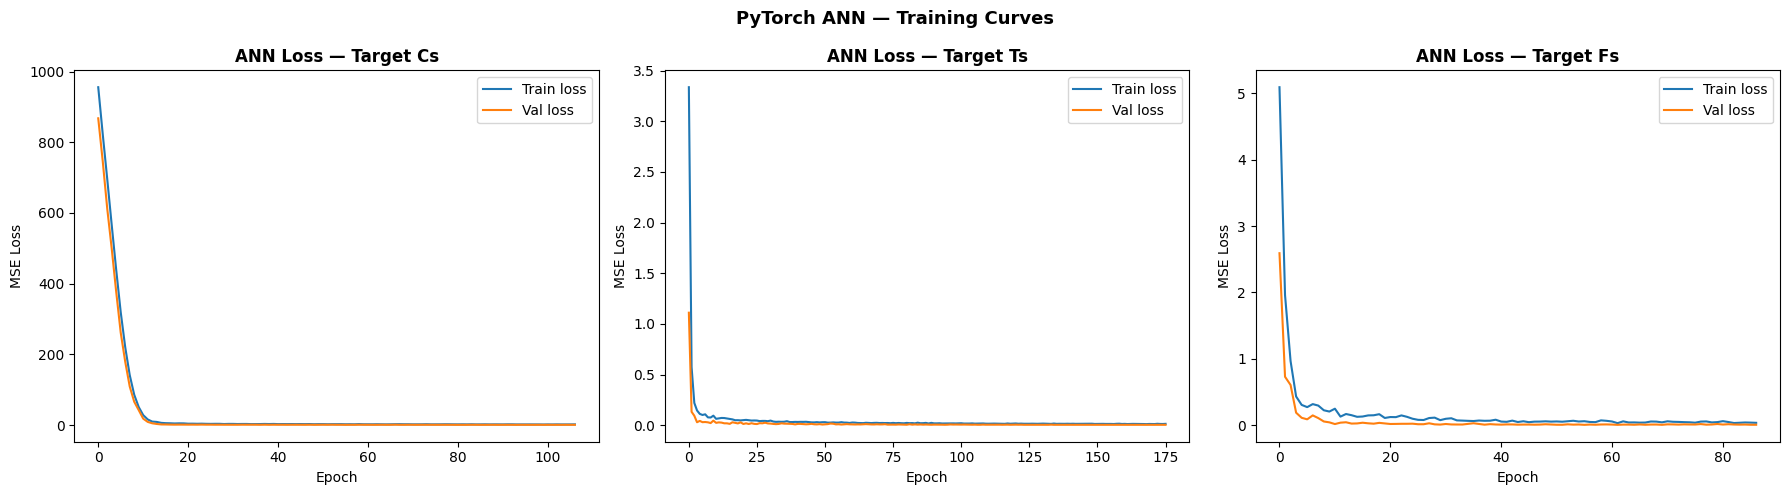

In [21]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, hist) in zip(axes, ann_histories.items()):
    ax.plot(hist['train_loss'], label='Train loss')
    ax.plot(hist['val_loss'],   label='Val loss')
    ax.set_title(f'ANN Loss — Target {name}', fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss')
    ax.legend()
plt.suptitle('PyTorch ANN — Training Curves', fontweight='bold', fontsize=13)
plt.tight_layout(); plt.show()


In [22]:

rows = []

sklearn_models = {
    'Ridge'      : lr_results,
    'NaiveBayes' : nb_results,
    'XGBoost'    : xgb_results,
    'LightGBM'   : lgb_results,
}

for mname, mdict in sklearn_models.items():
    for tname, col in TARGETS.items():
        _, X_te,  _, y_te = splits[tname]
        mdl = mdict[tname]
        y_pred = mdl.predict(X_te)
        n_feat = mdl['pre'].transform(X_te[:1]).shape[1]
        m = metrics(y_te, y_pred, n_feat)
        rows.append({'Model': mname, 'Target': tname, **{k: round(v, 4) for k, v in m.items()}})

for tname in TARGETS:
    mdl, pre, _, Xte_t, _, y_te = ann_results[tname]
    y_pred = predict_ann(mdl, Xte_t)
    n_feat = Xte_t.shape[1]
    m = metrics(y_te, y_pred, n_feat)
    rows.append({'Model': 'ANN(PyTorch)', 'Target': tname,
                 **{k: round(v, 4) for k, v in m.items()}})

cmp = pd.DataFrame(rows)
print("=== TEST-SET COMPARISON (all models × all targets) ===\n")
print(cmp.pivot_table(index=['Target', 'Model'],
                      values=['RMSE','MAE','R²','Adj.R²']).round(4).to_string())


=== TEST-SET COMPARISON (all models × all targets) ===

                     Adj.R²     MAE    RMSE      R²
Target Model                                       
Cs     ANN(PyTorch)  0.9920  0.6216  0.8638  0.9921
       LightGBM      0.9955  0.4262  0.6525  0.9955
       NaiveBayes    0.8865  2.1726  3.2608  0.8881
       Ridge         0.9012  2.4213  3.0423  0.9026
       XGBoost       0.9953  0.4290  0.6608  0.9954
Fs     ANN(PyTorch)  0.9992  0.0474  0.0647  0.9993
       LightGBM      0.9996  0.0253  0.0482  0.9996
       NaiveBayes    0.9713  0.1129  0.3962  0.9720
       Ridge         0.9862  0.1990  0.2751  0.9865
       XGBoost       0.9996  0.0235  0.0458  0.9996
Ts     ANN(PyTorch)  0.9954  0.0454  0.0603  0.9955
       LightGBM      0.9973  0.0286  0.0464  0.9973
       NaiveBayes    0.8020  0.2559  0.3971  0.8053
       Ridge         0.9200  0.1891  0.2524  0.9213
       XGBoost       0.9972  0.0283  0.0475  0.9972


In [23]:
# 
best_rows = (cmp.sort_values('R²', ascending=False)
               .groupby('Target').first()
               .reset_index()[['Target','Model','RMSE','MAE','R²','Adj.R²']])
print("=== WINNER per Target ===")
print(best_rows.to_string(index=False))


=== WINNER per Target ===
Target    Model   RMSE    MAE     R²  Adj.R²
    Cs LightGBM 0.6525 0.4262 0.9955  0.9955
    Fs  XGBoost 0.0458 0.0235 0.9996  0.9996
    Ts LightGBM 0.0464 0.0286 0.9973  0.9973


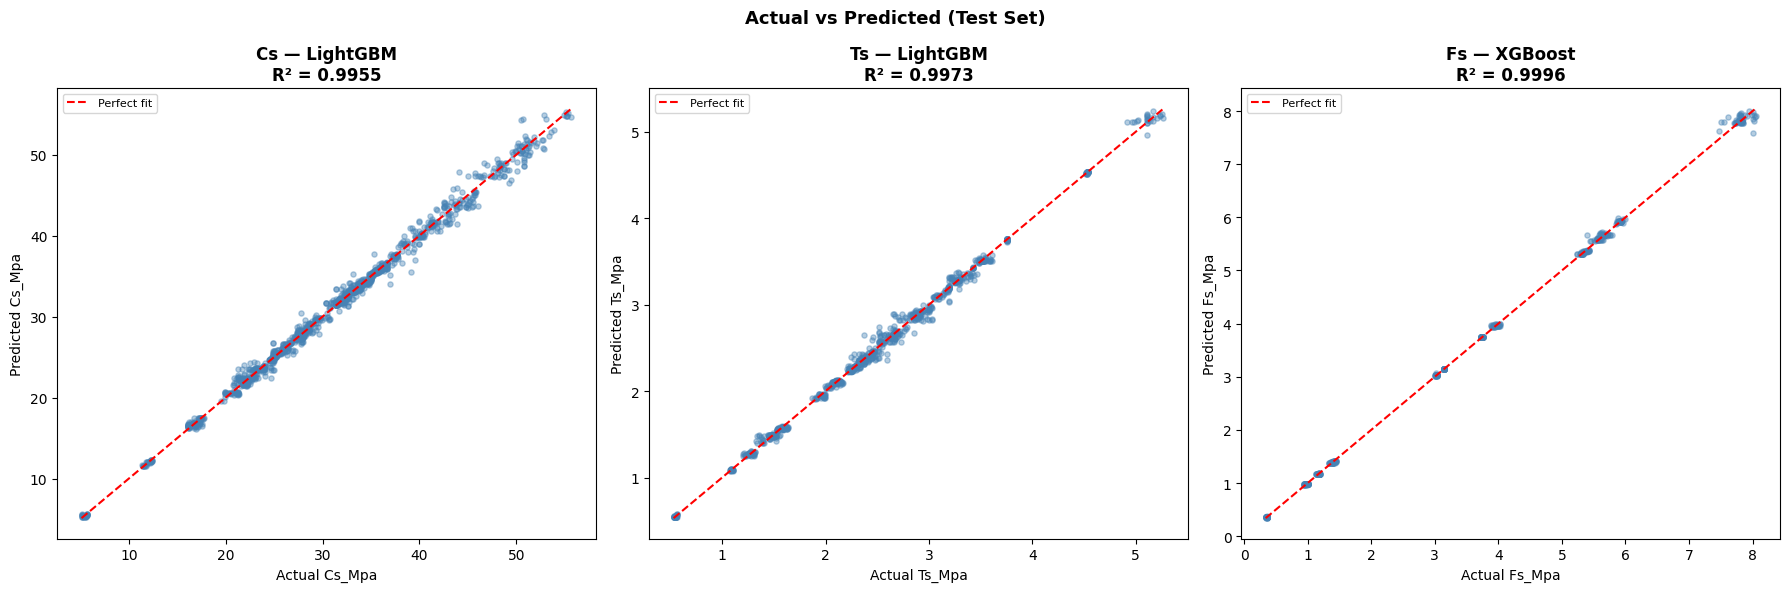

In [24]:
# Actual vs predicted plot
sklearn_lookup = {
    'Ridge'      : lr_results,
    'NaiveBayes' : nb_results,
    'XGBoost'    : xgb_results,
    'LightGBM'   : lgb_results,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (tname, col) in zip(axes, TARGETS.items()):
    winner = best_rows.set_index('Target').loc[tname, 'Model']
    _, X_te, _, y_te = splits[tname]

    if winner == 'ANN(PyTorch)':
        mdl, pre, _, Xte_t, _, y_te = ann_results[tname]
        y_pred = predict_ann(mdl, Xte_t)
    else:
        mdl    = sklearn_lookup[winner][tname]
        y_pred = mdl.predict(X_te)

    ax.scatter(y_te, y_pred, alpha=0.4, s=14, color='steelblue')
    lims = [min(y_te.min(), y_pred.min()), max(y_te.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', lw=1.5, label='Perfect fit')
    r2 = r2_score(y_te, y_pred)
    ax.set_xlabel(f'Actual {col}')
    ax.set_ylabel(f'Predicted {col}')
    ax.set_title(f'{tname} — {winner}\nR² = {r2:.4f}', fontweight='bold')
    ax.legend(fontsize=8)

plt.suptitle('Actual vs Predicted (Test Set)', fontweight='bold', fontsize=13)
plt.tight_layout(); plt.show()


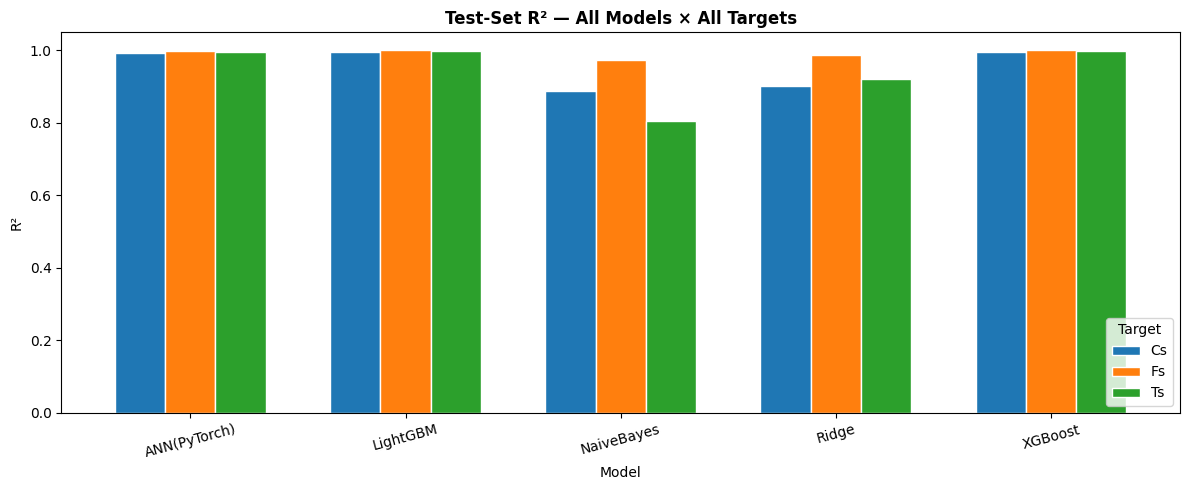

In [25]:
# ── Cell 27 · R² Bar Chart — All Models × All Targets ────────────────────────
pivot = cmp.pivot(index='Model', columns='Target', values='R²')
ax    = pivot.plot(kind='bar', figsize=(12, 5), edgecolor='white', width=0.7)
plt.title('Test-Set R² — All Models × All Targets', fontweight='bold')
plt.ylabel('R²'); plt.xticks(rotation=15)
plt.legend(title='Target', loc='lower right')
plt.tight_layout(); plt.show()
